In [5]:

import pandas as pd
from pathlib import Path

# Create a directory for assignment outputs
Path("data").mkdir(exist_ok=True)

# UCI Heart Disease dataset: Cleveland subset
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/"
    "processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

# Download and load the data
df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

# Save a local copy
df.to_csv("data/heart_disease_raw.csv", index=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print("\nColumn information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
th

In [6]:

# Load the raw dataset saved in Step 1
df = pd.read_csv("data/heart_disease_raw.csv")

print("Missing values before cleaning:")
print(df[["ca", "thal"]].isnull().sum())

# Remove rows with missing values
# Only 6 of the 303 records have missing entries
df_clean = df.dropna().copy()

# Convert original target:
# 0 = no disease
# 1, 2, 3, 4 = disease present
df_clean["target"] = (
    df_clean["target"] > 0
).astype(int)

# Convert coded categorical features to integer categories
categorical_cols = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype(int)

# Save the cleaned dataset
Path("data").mkdir(exist_ok=True)
df_clean.to_csv("data/heart_disease_clean.csv", index=False)

print("\nCleaned dataset shape:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("\nBinary target distribution:")
print(df_clean["target"].value_counts().sort_index())

display(df_clean.head())


Missing values before cleaning:
ca      4
thal    2
dtype: int64

Cleaned dataset shape: (297, 14)

Missing values after cleaning:
0

Binary target distribution:
target
0    160
1    137
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


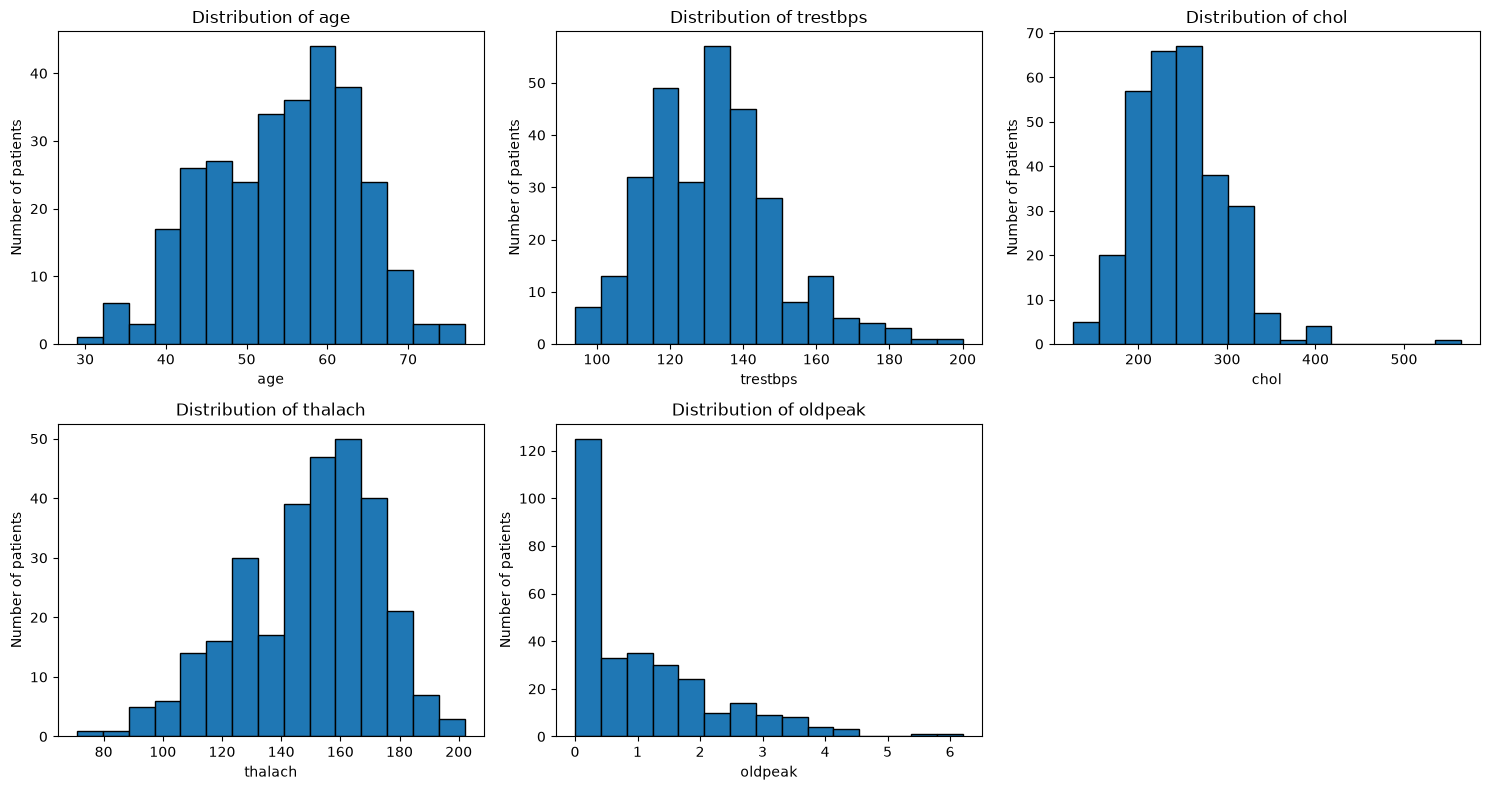

In [7]:

import matplotlib.pyplot as plt

Path("plots").mkdir(exist_ok=True)

# Load the cleaned dataset
df_clean = pd.read_csv("data/heart_disease_clean.csv")

# Select continuous numerical features
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Plot distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    axes[i].hist(
        df_clean[col],
        bins=15,
        edgecolor="black"
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of patients")

axes[-1].axis("off")

plt.tight_layout()
plt.savefig("plots/feature_histograms.png", dpi=150)
plt.show()


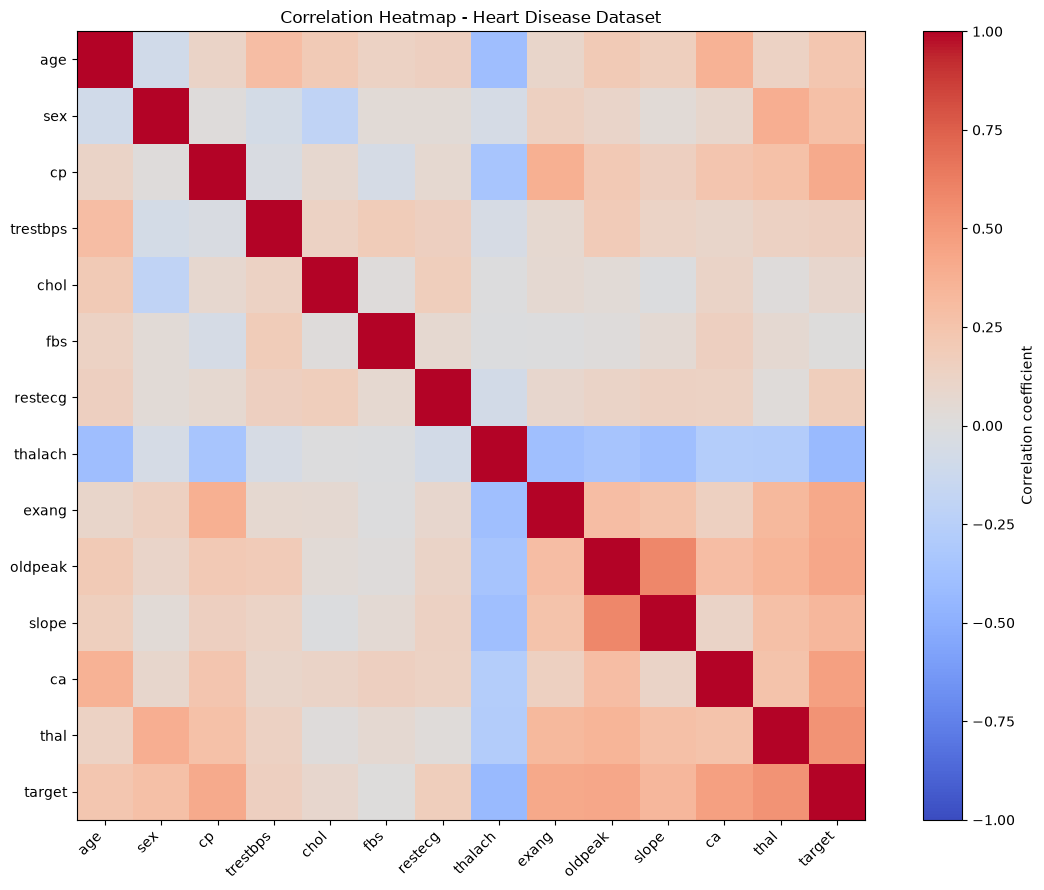

In [8]:

correlation = df_clean.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Heatmap - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("plots/correlation_heatmap.png", dpi=150)
plt.show()


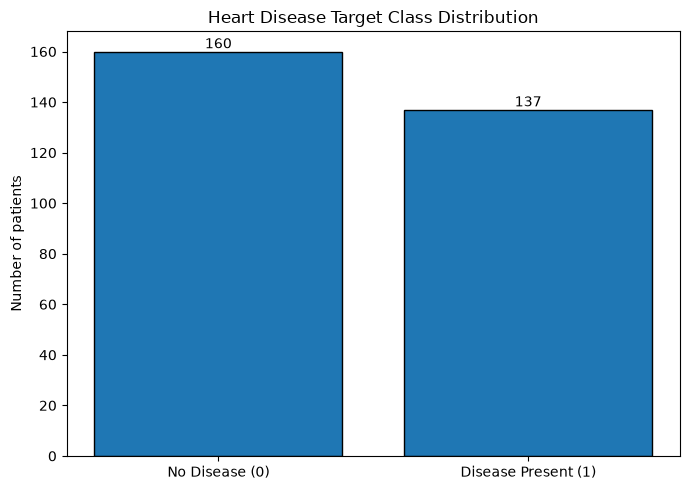

In [9]:

class_counts = df_clean["target"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["No Disease (0)", "Disease Present (1)"],
    class_counts.values,
    edgecolor="black"
)

plt.title("Heart Disease Target Class Distribution")
plt.ylabel("Number of patients")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("plots/class_balance.png", dpi=150)
plt.show()


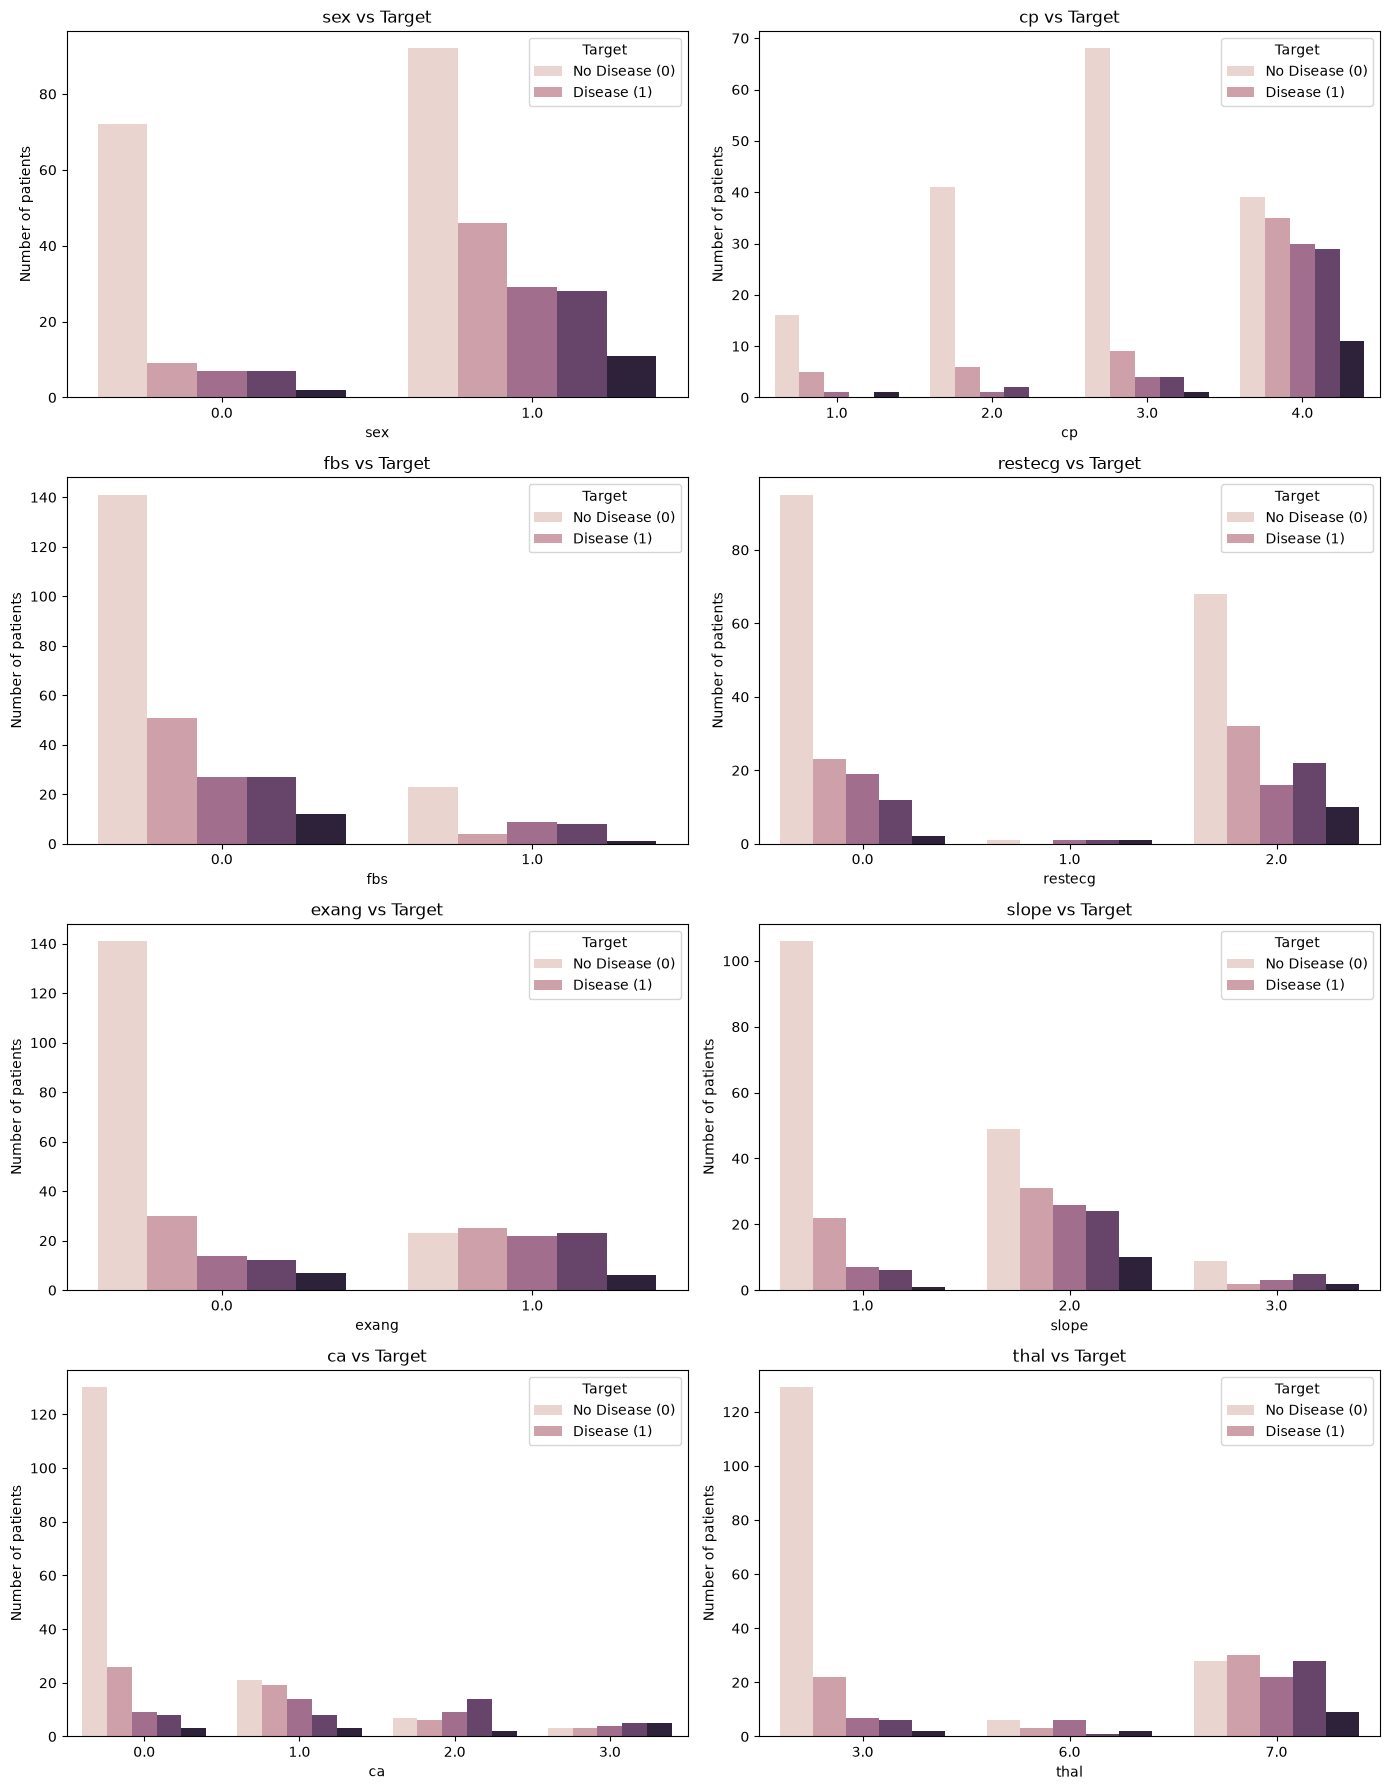

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
from pathlib import Path

# Use the cleaned DataFrame from your existing EDA notebook
df_eda = df.copy()

# Create output folder if it does not exist
Path("plots").mkdir(exist_ok=True)

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    sns.countplot(
        data=df_eda,
        x=feature,
        hue="target",
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Target")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of patients")
    axes[i].legend(
        title="Target",
        labels=["No Disease (0)", "Disease (1)"]
    )

plt.tight_layout()
plt.savefig("plots/categorical_features_vs_target.png", dpi=150)
plt.show()

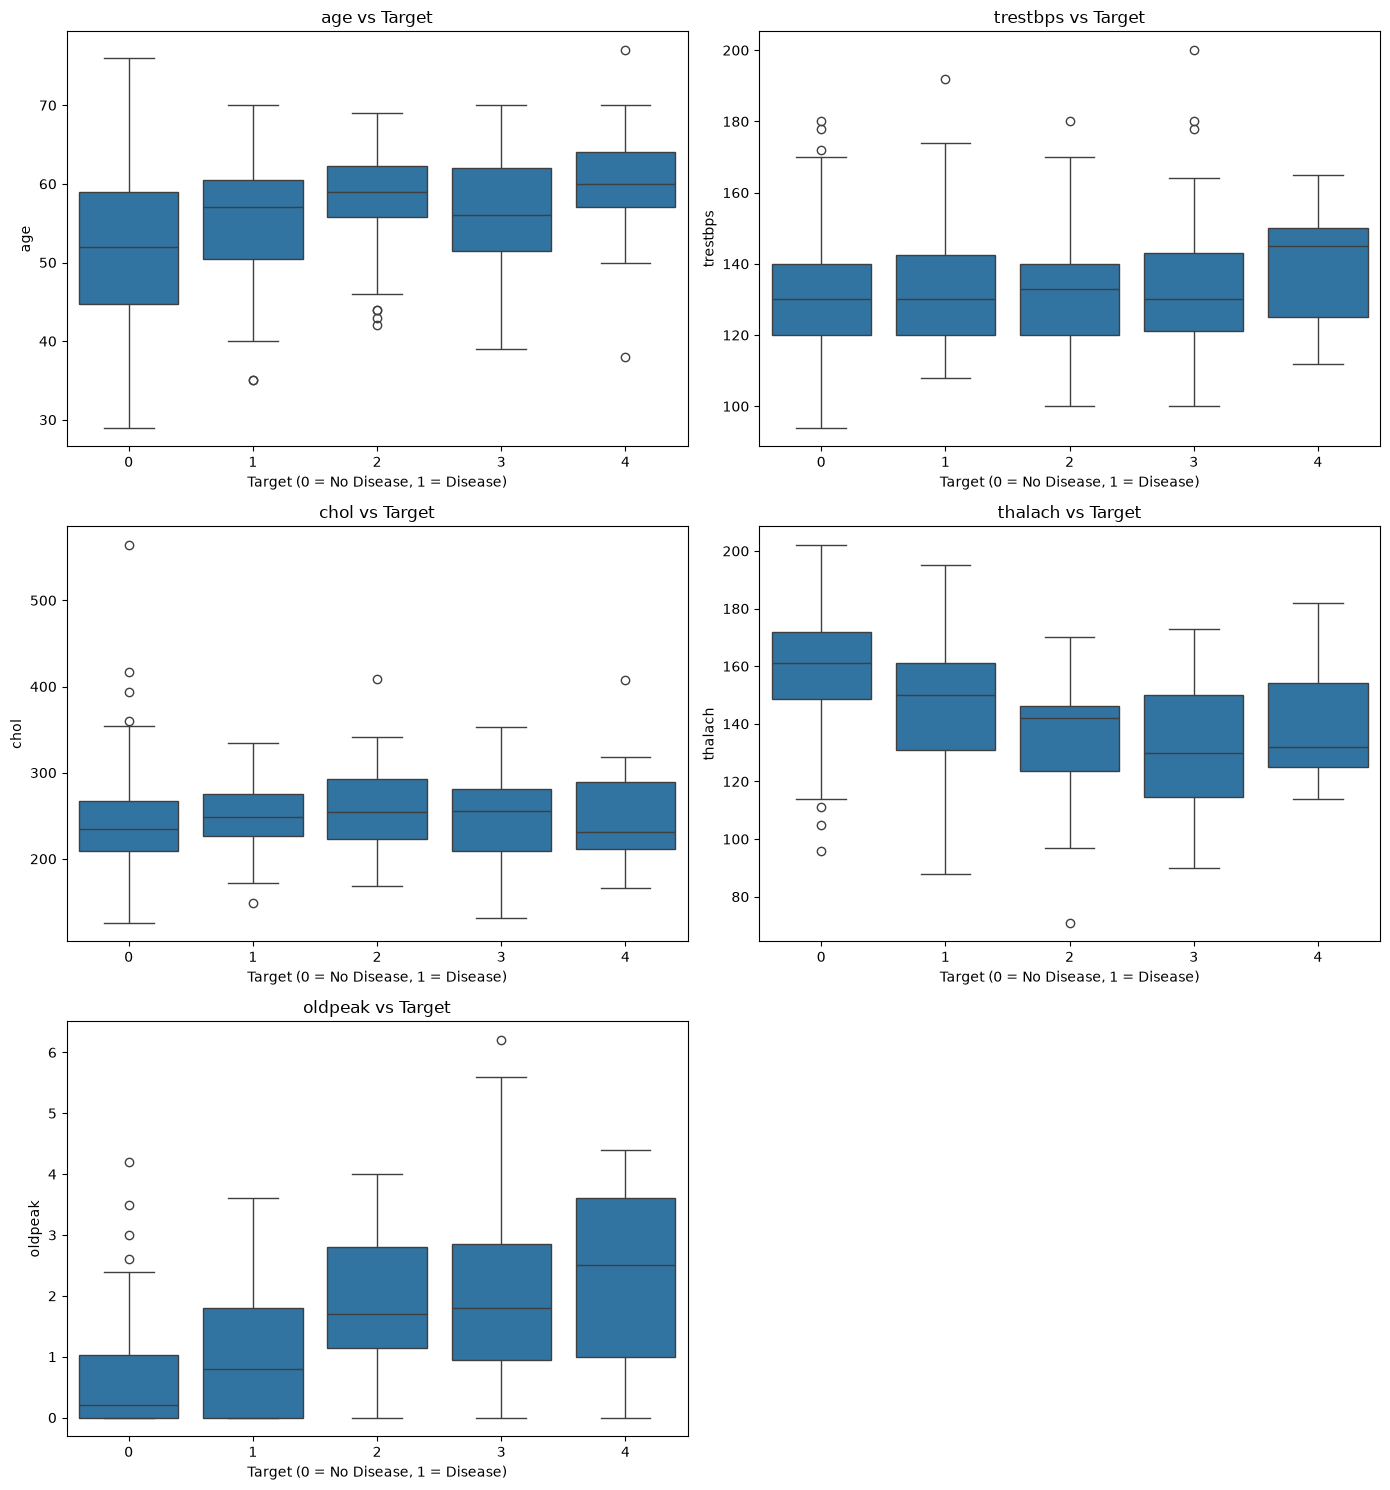

In [12]:
numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df_eda,
        x="target",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Target")
    axes[i].set_xlabel("Target (0 = No Disease, 1 = Disease)")
    axes[i].set_ylabel(feature)

# Hide the unused sixth subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig("plots/numerical_features_vs_target.png", dpi=150)
plt.show()

In [11]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Load cleaned data
df_clean = pd.read_csv("data/heart_disease_clean.csv")

# Separate features and target
X = df_clean.drop(columns=["target"])
y = df_clean["target"]

# Numerical measurements
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Categorical codes
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Split before fitting preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create complete model pipelines
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight=None
    ))
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Feature count before encoding:", X.shape[1])
print("Preprocessing and model pipelines created successfully.")


Training records: 237
Testing records: 60
Feature count before encoding: 13
Preprocessing and model pipelines created successfully.


In [17]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

# Five-fold stratified cross-validation on training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_results = []
fitted_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Fit on the complete training split
    model.fit(X_train, y_train)
    fitted_models[name] = model

    # Evaluate once on the held-out test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Disease", "Disease Present"],
        zero_division=0
    ))

results_df = pd.DataFrame(cv_results)
display(results_df.round(3))

Path("results").mkdir(exist_ok=True)
results_df.to_csv("results/model_comparison.csv", index=False)



Training Logistic Regression...
                 precision    recall  f1-score   support

     No Disease       0.78      0.91      0.84        32
Disease Present       0.87      0.71      0.78        28

       accuracy                           0.82        60
      macro avg       0.83      0.81      0.81        60
   weighted avg       0.82      0.82      0.81        60


Training Random Forest...
                 precision    recall  f1-score   support

     No Disease       0.82      0.88      0.85        32
Disease Present       0.85      0.79      0.81        28

       accuracy                           0.83        60
      macro avg       0.83      0.83      0.83        60
   weighted avg       0.83      0.83      0.83        60



,Model,CV Accuracy,CV Precision,CV Recall,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test ROC-AUC
0,Logistic Regression,0.822,0.839,0.769,0.902,0.817,0.870,0.714,0.941
1,Random Forest,0.798,0.815,0.742,0.897,0.833,0.846,0.786,0.934


In [18]:

from sklearn.model_selection import GridSearchCV

lr_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

lr_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=lr_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

lr_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(lr_search.best_params_)
print("Best mean CV ROC-AUC:", round(lr_search.best_score_, 4))


Best Logistic Regression parameters:
{'classifier__C': 1, 'classifier__class_weight': None}
Best mean CV ROC-AUC: 0.9024


In [19]:

rf_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

rf_search = GridSearchCV(
    estimator=random_forest_model,
    param_grid=rf_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best mean CV ROC-AUC:", round(rf_search.best_score_, 4))


Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Best mean CV ROC-AUC: 0.9007


In [20]:


import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

Path("results").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)

tuned_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "CV ROC-AUC": (
            lr_search.best_score_
            if name == "Logistic Regression"
            else rf_search.best_score_
        ),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)
display(tuned_results_df.round(3))

tuned_results_df.to_csv(
    "results/tuned_model_comparison.csv",
    index=False
)

# Select using cross-validation ROC-AUC, not test-set performance
if lr_search.best_score_ >= rf_search.best_score_:
    final_model = lr_search.best_estimator_
    selected_model_name = "Logistic Regression"
else:
    final_model = rf_search.best_estimator_
    selected_model_name = "Random Forest"

# Save the entire preprocessing + model pipeline
joblib.dump(final_model, "models/heart_disease_pipeline.joblib")

print("Selected model:", selected_model_name)
print("Saved model to models/heart_disease_pipeline.joblib")


,Model,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test ROC-AUC
0,Logistic Regression,0.902,0.817,0.870,0.714,0.941
1,Random Forest,0.901,0.833,0.846,0.786,0.943


Selected model: Logistic Regression
Saved model to models/heart_disease_pipeline.joblib


In [21]:

%pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 61.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [23]:

import mlflow
from pathlib import Path

# Create directories
Path("results").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
Path("mlflow_data").mkdir(exist_ok=True)

# Use SQLite instead of the deprecated file-based backend
mlflow.set_tracking_uri("sqlite:///mlflow_data/mlflow.db")

# Create or select the experiment
mlflow.set_experiment("Heart_Disease_Classification")

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment configured successfully!")


2026/10/11 15:20:02 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 15:20:02 INFO mlflow.store.db.utils: Updating database tables
2026/10/11 15:20:06 INFO mlflow.tracking.fluent: Experiment with name 'Heart_Disease_Classification' does not exist. Creating a new experiment.


MLflow tracking URI: sqlite:///mlflow_data/mlflow.db
MLflow experiment configured successfully!


In [24]:
models_to_track = {
    "Logistic_Regression": lr_search.best_estimator_,
    "Random_Forest": rf_search.best_estimator_
}

In [26]:

experiment = mlflow.get_experiment_by_name(
    "Heart_Disease_Classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print("Number of tracked runs:", len(runs))
print("\nAvailable columns:")
print(runs.columns.tolist())

display(runs.head())


Number of tracked runs: 0

Available columns:
['run_id', 'experiment_id', 'status', 'artifact_uri', 'start_time', 'end_time']


,run_id,experiment_id,status,artifact_uri,start_time,end_time


In [29]:

import mlflow
from pathlib import Path

import numpy as np
from sklearn.compose._column_transformer import _RemainderColsList

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score
)

mlflow.set_tracking_uri("sqlite:///mlflow_data/mlflow.db")
mlflow.set_experiment("Heart_Disease_Classification")

models_to_track = {
    "Logistic_Regression": lr_search.best_estimator_,
    "Random_Forest": rf_search.best_estimator_
}

searches = {
    "Logistic_Regression": lr_search,
    "Random_Forest": rf_search
}

for name, model in models_to_track.items():
    search = searches[name]

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    with mlflow.start_run(run_name=name):
        mlflow.log_params({
            key: str(value)
            for key, value in search.best_params_.items()
        })

        mlflow.log_metrics({
            "cv_roc_auc": float(search.best_score_),
            "test_accuracy": float(
                accuracy_score(y_test, predictions)
            ),
            "test_precision": float(
                precision_score(
                    y_test, predictions, zero_division=0
                )
            ),
            "test_recall": float(
                recall_score(
                    y_test, predictions, zero_division=0
                )
            ),
            "test_roc_auc": float(
                roc_auc_score(y_test, probabilities)
            )
        })


        mlflow.sklearn.log_model(
            sk_model=model,
            name="model",
            skops_trusted_types=[
                "numpy.dtype",
                "sklearn.compose._column_transformer._RemainderColsList",
                "sklearn.tree._tree.Tree"
            ]
        )


        # Log available project evidence
        for folder in ["plots", "results"]:
            for file in Path(folder).glob("*"):
                if file.is_file():
                    mlflow.log_artifact(str(file))

        print(f"Successfully logged: {name}")

print("Logging completed.")


Successfully logged: Logistic_Regression
Successfully logged: Random_Forest
Logging completed.


In [30]:

import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow_data/mlflow.db")

experiment = mlflow.get_experiment_by_name(
    "Heart_Disease_Classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

print("Total recorded runs:", len(runs))

columns = [
    "tags.mlflow.runName",
    "status",
    "metrics.cv_roc_auc",
    "metrics.test_accuracy",
    "metrics.test_precision",
    "metrics.test_recall",
    "metrics.test_roc_auc"
]

display(runs[[c for c in columns if c in runs.columns]])


Total recorded runs: 5


,tags.mlflow.runName,status,metrics.cv_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc
0,Random_Forest,FINISHED,0.900653,0.833333,0.846154,0.785714,0.943080
1,Logistic_Regression,FINISHED,0.902418,0.816667,0.869565,0.714286,0.940848
2,Random_Forest,FAILED,0.900653,0.833333,0.846154,0.785714,0.943080
3,Logistic_Regression,FINISHED,0.902418,0.816667,0.869565,0.714286,0.940848
4,Logistic_Regression,FAILED,0.902418,0.816667,0.869565,0.714286,0.940848


In [31]:

import joblib
import json
from datetime import datetime, timezone

Path("models").mkdir(exist_ok=True)

# Save the selected preprocessing + model pipeline
joblib.dump(
    final_model,
    "models/heart_disease_pipeline.joblib"
)

# Save information describing the model
metadata = {
    "project": "Heart Disease Classification",
    "selected_model": selected_model_name,
    "target": {
        "0": "No disease",
        "1": "Disease present"
    },
    "input_features": list(X.columns),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "selection_metric": "Mean cross-validation ROC-AUC",
    "selection_score": float(
        max(lr_search.best_score_, rf_search.best_score_)
    ),
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model and metadata saved successfully.")
print("Model:", "models/heart_disease_pipeline.joblib")
print("Metadata:", "models/model_metadata.json")


Model and metadata saved successfully.
Model: models/heart_disease_pipeline.joblib
Metadata: models/model_metadata.json


In [32]:

import numpy as np

# Load the saved model
loaded_model = joblib.load(
    "models/heart_disease_pipeline.joblib"
)

# Use two records from the held-out test data
sample_input = X_test.iloc[:2].copy()

# Make predictions and probabilities
predictions = loaded_model.predict(sample_input)
probabilities = loaded_model.predict_proba(sample_input)[:, 1]

print("Input records:")
display(sample_input)

print("\nPredictions (0 = no disease, 1 = disease present):")
print(predictions)

print("\nModel-estimated probability of class 1:")
print(np.round(probabilities, 4))

# Confirm predictions are identical to the original pipeline
original_predictions = final_model.predict(sample_input)

assert np.array_equal(predictions, original_predictions), (
    "Loaded model predictions do not match!"
)

print("\nPASS: Saved model loaded and predictions match.")


Input records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
290,41.0,1,2,120.0,157.0,0,0,182.0,0,0.0,1,0,3
239,49.0,0,4,130.0,269.0,0,0,163.0,0,0.0,1,0,3



Predictions (0 = no disease, 1 = disease present):
[0 0]

Model-estimated probability of class 1:
[0.0254 0.0583]

PASS: Saved model loaded and predictions match.


In [33]:

from importlib.metadata import version, PackageNotFoundError

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "joblib",
    "mlflow",
    "matplotlib"
]

lines = []

for package in packages:
    try:
        installed_version = version(package)
        lines.append(f"{package}=={installed_version}")
    except PackageNotFoundError:
        print(f"Warning: {package} is not installed")

with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("requirements.txt created:")
print("\n".join(lines))


requirements.txt created:
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
mlflow==3.17.0
matplotlib==3.10.0


In [34]:

%pip install -q fastapi uvicorn httpx

In [35]:

from importlib.metadata import version

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "joblib",
    "mlflow",
    "matplotlib",
    "fastapi",
    "uvicorn",
    "httpx"
]

with open("requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

print(open("requirements.txt").read())

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
mlflow==3.17.0
matplotlib==3.10.0
fastapi==0.141.1
uvicorn==0.54.0
httpx==0.28.1



In [36]:

%%writefile app.py
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

MODEL_PATH = Path(__file__).parent / "models" / "heart_disease_pipeline.joblib"

model = joblib.load(MODEL_PATH)

app = FastAPI(
    title="Heart Disease Classification API",
    description="Educational ML prediction API",
    version="1.0.0"
)


class PatientInput(BaseModel):
    age: float = Field(ge=1, le=120)
    sex: int = Field(ge=0, le=1)
    cp: int = Field(ge=1, le=4)
    trestbps: float = Field(gt=0)
    chol: float = Field(gt=0)
    fbs: int = Field(ge=0, le=1)
    restecg: int = Field(ge=0, le=2)
    thalach: float = Field(gt=0)
    exang: int = Field(ge=0, le=1)
    oldpeak: float
    slope: int = Field(ge=1, le=3)
    ca: int = Field(ge=0, le=3)
    thal: int = Field(ge=3, le=7)


@app.get("/")
def home():
    return {"message": "Heart Disease Classification API is running"}


@app.get("/health")
def health():
    return {"status": "healthy", "model_loaded": model is not None}


@app.post("/predict")
def predict(patient: PatientInput):
    patient_data = pd.DataFrame(
        [patient.model_dump()]
    )

    prediction = int(model.predict(patient_data)[0])
    probability = float(
        model.predict_proba(patient_data)[0, 1]
    )

    return {
        "prediction": prediction,
        "prediction_label": (
            "Disease present" if prediction == 1
            else "No disease"
        ),
        "probability_class_1": round(probability, 4),
        "note": (
            "Educational model output only; "
            "not a medical diagnosis."
        )
    }


Writing app.py


In [37]:

from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

# Check the API health
health_response = client.get("/health")
print("Health status:", health_response.status_code)
print(health_response.json())

# Sample input using the dataset's feature schema
sample_patient = {
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trestbps": 130,
    "chol": 250,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.0,
    "slope": 2,
    "ca": 0,
    "thal": 3
}

prediction_response = client.post(
    "/predict",
    json=sample_patient
)

print("\nPrediction status:", prediction_response.status_code)
print(prediction_response.json())

assert health_response.status_code == 200
assert prediction_response.status_code == 200
assert prediction_response.json()["prediction"] in [0, 1]
assert 0 <= prediction_response.json()["probability_class_1"] <= 1

print("\nPASS: API health and prediction tests succeeded.")


Health status: 200
{'status': 'healthy', 'model_loaded': True}

Prediction status: 200
{'prediction': 0, 'prediction_label': 'No disease', 'probability_class_1': 0.2696, 'note': 'Educational model output only; not a medical diagnosis.'}

PASS: API health and prediction tests succeeded.


In [38]:

!mkdir -p tests
%pip install -q pytest


In [41]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir("."))
print("Test files:", os.listdir("tests"))

Current directory: /content
Files: ['.config', 'mlruns', 'tests', '__pycache__', '.pytest_cache', 'requirements.txt', 'results', 'data', 'mlflow_data', 'app.py', 'models', 'plots', 'sample_data']
Test files: ['test_app.py', '__pycache__']


In [42]:

%%writefile tests/test_app.py
import sys
from pathlib import Path

# Add the project root (/content) to Python's import path
PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT))

from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

VALID_PATIENT = {
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trestbps": 130,
    "chol": 250,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.0,
    "slope": 2,
    "ca": 0,
    "thal": 3
}


def test_home_endpoint():
    response = client.get("/")
    assert response.status_code == 200
    assert "message" in response.json()


def test_health_endpoint():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "healthy"
    assert response.json()["model_loaded"] is True


def test_predict_valid_patient():
    response = client.post("/predict", json=VALID_PATIENT)
    assert response.status_code == 200

    result = response.json()
    assert result["prediction"] in [0, 1]
    assert result["prediction_label"] in [
        "No disease", "Disease present"
    ]
    assert 0 <= result["probability_class_1"] <= 1


def test_predict_rejects_invalid_input():
    invalid_patient = VALID_PATIENT.copy()
    invalid_patient["age"] = 500

    response = client.post("/predict", json=invalid_patient)
    assert response.status_code == 422


Overwriting tests/test_app.py


In [43]:

!python -m pytest -v tests/test_app.py

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: langsmith-0.14.2, typeguard-4.6.0, anyio-4.15.1, platformdirs-4.12.2
collected 4 items                                                              

tests/test_app.py::test_home_endpoint PASSED                             [ 25%]
tests/test_app.py::test_health_endpoint PASSED                           [ 50%]
tests/test_app.py::test_predict_valid_patient PASSED                     [ 75%]
tests/test_app.py::test_predict_rejects_invalid_input PASSED             [100%]

============================== 4 passed in 2.75s ===============================


In [44]:

from pathlib import Path

Path(".github/workflows").mkdir(parents=True, exist_ok=True)
print("Workflow directory created.")

Workflow directory created.


In [46]:

from pathlib import Path

required_files = [
    "app.py",
    "requirements.txt",
    "models/heart_disease_pipeline.joblib",
    "models/model_metadata.json",
    "tests/test_app.py",
    ".github/workflows/ci.yml"
]

for filename in required_files:
    print(
        "OK" if Path(filename).exists() else "MISSING",
        filename
    )

OK app.py
OK requirements.txt
OK models/heart_disease_pipeline.joblib
OK models/model_metadata.json
OK tests/test_app.py
OK .github/workflows/ci.yml


In [45]:

%%writefile .github/workflows/ci.yml
name: MLOps CI Pipeline

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip

      - name: Install dependencies
        run: pip install -r requirements.txt

      - name: Check Python syntax
        run: python -m compileall -q app.py tests

      - name: Run unit tests
        run: python -m pytest -v tests/

Writing .github/workflows/ci.yml


In [47]:
print(open("requirements.txt").read())

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
mlflow==3.17.0
matplotlib==3.10.0
fastapi==0.141.1
uvicorn==0.54.0
httpx==0.28.1



In [48]:

from importlib.metadata import version

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "joblib",
    "fastapi",
    "uvicorn",
    "httpx",
    "pytest"
]

with open("requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

print(open("requirements.txt").read())


numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
fastapi==0.141.1
uvicorn==0.54.0
httpx==0.28.1
pytest==8.4.2



In [49]:

%%writefile .github/workflows/ci.yml
name: MLOps CI Pipeline

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.13"
          cache: pip

      - name: Install dependencies
        run: pip install -r requirements.txt

      - name: Install linter
        run: pip install ruff

      - name: Lint Python files
        run: ruff check app.py tests/

      - name: Check Python syntax
        run: python -m compileall -q app.py tests

      - name: Run unit tests
        run: python -m pytest -v tests/


Overwriting .github/workflows/ci.yml


In [50]:

from pathlib import Path
import shutil

root = Path("/content")
project = root / "mlops-heart-disease"

# Create project directories
folders = [
    "data",
    "notebooks",
    "plots",
    "results",
    "models",
    "src",
    "tests",
    ".github/workflows"
]

for folder in folders:
    (project / folder).mkdir(parents=True, exist_ok=True)

# Copy existing project files
files_to_copy = [
    "app.py",
    "requirements.txt",
    "data/heart_disease_raw.csv",
    "data/heart_disease_clean.csv",
    "plots/feature_histograms.png",
    "plots/correlation_heatmap.png",
    "plots/class_balance.png",
    "results/model_comparison.csv",
    "results/tuned_model_comparison.csv",
    "models/heart_disease_pipeline.joblib",
    "models/model_metadata.json",
    "tests/test_app.py",
    ".github/workflows/ci.yml"
]

for filename in files_to_copy:
    source = root / filename
    destination = project / filename

    if source.is_file():
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("MISSING:", filename)

print("\nProject directory:", project)


Copied: app.py
Copied: requirements.txt
Copied: data/heart_disease_raw.csv
Copied: data/heart_disease_clean.csv
Copied: plots/feature_histograms.png
Copied: plots/correlation_heatmap.png
Copied: plots/class_balance.png
Copied: results/model_comparison.csv
Copied: results/tuned_model_comparison.csv
Copied: models/heart_disease_pipeline.joblib
Copied: models/model_metadata.json
Copied: tests/test_app.py
Copied: .github/workflows/ci.yml

Project directory: /content/mlops-heart-disease
